# Intelligent Predictive Maintenance and Machine Failure Monitoring System
**Unit 4 – Sequential Data (HMM) · Industry-Oriented Project 1**  
Team: Sai Ishita Chilukuri (RA2411003010608), Himanshu Roy (RA2411003010614), Munish Abhiram B (RA2411003010629), Shriyans Patro (RA2411003010636) · SRM Institute of Science and Technology, Kattankulatham

**Workflow followed (as required):** Dataset → preprocessing → sequence construction → model formulation → algorithm implementation → inference/estimation → evaluation → visualization → interpretation.

### Disclosures (required by the project brief)
* **Synthetic data:** NASA C-MAPSS is *simulated* turbofan data produced by a physics-based engine simulator (not measurements from real engines). No additional synthetic data was created by us.
* **Access restrictions:** none – the dataset is public (NASA Prognostics Center of Excellence repository). We download a public mirror of the same files.
* **Educational prototype:** this is a coursework prototype, **not** a production maintenance or safety system.
* **Dataset choice:** NASA C-MAPSS sub-set **FD001** (one operating condition, one fault mode: HPC degradation; 100 train engines run to failure, 100 test engines truncated before failure, true RUL provided).

## 0. Setup and reproducibility

In [1]:
import sys, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
SEED = 42
random.seed(SEED); np.random.seed(SEED)

from pmhmm.data import load_fd001, health_band, HEALTHY_RUL, FAULT_RUL
from pmhmm.features import (SENSORS, CONSTANT_SENSORS, find_constant_sensors, causal_window_features,
                            FeaturePipeline, split_engines, to_sequences)
from pmhmm.hmm_scratch import GaussianHMM
from pmhmm.evaluate import first_alert, evaluate_alerts, tune_threshold
from pmhmm import pipeline as P

FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25, "axes.spines.top": False, "axes.spines.right": False})
def savefig(name): plt.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=170)
print("random seed:", SEED)

random seed: 42


## 1. Dataset

In [2]:
train, test = load_fd001()          # downloads the 3 public FD001 files to data/raw/ on first run
print("train:", train.shape, "| engines:", train.unit.nunique(), "| cycles per engine: min/mean/max =",
      train.groupby('unit').cycle.max().min(), round(train.groupby('unit').cycle.max().mean(),1), train.groupby('unit').cycle.max().max())
print("test :", test.shape,  "| engines:", test.unit.nunique(), "| observed cycles per engine: min/mean/max =",
      test.groupby('unit').cycle.max().min(), round(test.groupby('unit').cycle.max().mean(),1), test.groupby('unit').cycle.max().max())
train.head()

train: (20631, 27) | engines: 100 | cycles per engine: min/mean/max = 128 206.3 362
test : (13096, 27) | engines: 100 | observed cycles per engine: min/mean/max = 31 131.0 303


,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


Each row is one operating **cycle** of one engine: 3 operating settings + 21 sensors. The engine starts healthy and a fault (HPC degradation) grows until failure.
**Ground-truth RUL** (remaining useful life) is derived from the cycle counter (train) or from `RUL_FD001.txt` (test). We use it **only for evaluation**, never to train the HMM (the HMM is unsupervised).
Evaluation bands: *healthy* RUL > 100, *degrading* 30 < RUL ≤ 100, *fault* RUL ≤ 30.

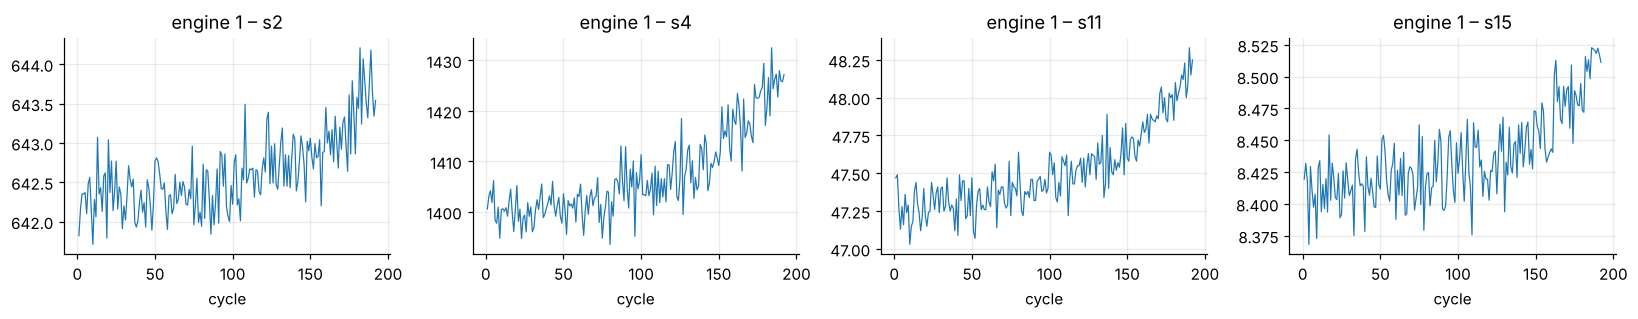

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


In [3]:
u = 1
e = train[train.unit == u]
fig, ax = plt.subplots(1, 4, figsize=(15, 3))
for a, s in zip(ax, ["s2", "s4", "s11", "s15"]):
    a.plot(e.cycle, e[s], lw=.8); a.set_title(f"engine {u} – {s}"); a.set_xlabel("cycle")
plt.tight_layout(); savefig("fig01_raw_sensors"); plt.show()
life = train.groupby("unit").cycle.max()
print(life.describe().round(1))

## 2. Preprocessing

In [4]:
print("missing values  train/test:", int(train.isna().sum().sum()), "/", int(test.isna().sum().sum()))
const = find_constant_sensors(train)
print("constant / non-informative sensors detected from data:", const)
assert sorted(const) == sorted(CONSTANT_SENSORS)      # the list used by the pipeline is data-driven
print("kept sensors (%d):" % len(SENSORS), SENSORS)

missing values  train/test: 0 / 0
constant / non-informative sensors detected from data: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
kept sensors (14): ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


**Cleaning steps:** (1) no missing values were found; (2) 7 constant sensors are dropped (zero information); (3) a **trailing (causal) rolling mean over 10 cycles** denoises each sensor – cycle *t* uses only cycles ≤ *t*, so the same code works online and cannot leak future information; (4) sensors are standardised (z-score) and projected with **PCA** (3 components) – both **fitted on training engines only**.

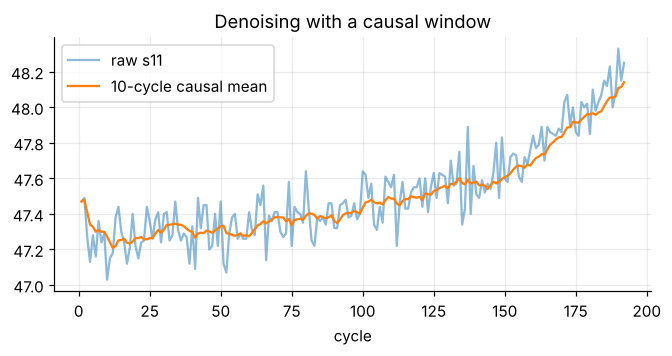

In [5]:
sm = causal_window_features(train)
e_raw, e_sm = train[train.unit == 1], sm[sm.unit == 1]
plt.figure(figsize=(7, 3)); plt.plot(e_raw.cycle, e_raw.s11, alpha=.5, label="raw s11"); plt.plot(e_sm.cycle, e_sm.s11, label="10-cycle causal mean")
plt.legend(); plt.xlabel("cycle"); plt.title("Denoising with a causal window"); savefig("fig02_smoothing"); plt.show()

## 3. Sequence construction (and leakage control)

In [6]:
fit_units, val_units = split_engines(train.unit.unique(), val_frac=0.3, seed=SEED)
print(f"fit engines: {len(fit_units)} | validation engines: {len(val_units)} | test engines (official test set): {test.unit.nunique()}")
assert set(fit_units).isdisjoint(val_units)

fp = FeaturePipeline(n_components=3).fit(train[train.unit.isin(fit_units)])     # scaler + PCA see FIT engines only
print("PCA explained variance:", fp.pca_.explained_variance_ratio_.round(4), "| total", fp.pca_.explained_variance_ratio_.sum().round(4))
seq_train = to_sequences(fp.transform(train), 3)       # {engine: (T, 3) array in cycle order}
seq_test  = to_sequences(fp.transform(test), 3)
rul_train = {int(u): g.sort_values('cycle').rul.to_numpy() for u, g in train.groupby('unit')}
rul_test  = {int(u): g.sort_values('cycle').rul.to_numpy() for u, g in test.groupby('unit')}
print("example sequence shape (engine 1):", seq_train[1].shape)

fit engines: 70 | validation engines: 30 | test engines (official test set): 100
PCA explained variance: [0.8104 0.1547 0.006 ] | total 0.971


example sequence shape (engine 1): (192, 3)


**Leakage safeguards (all checked in code / unit tests):**
1. Each engine is an independent run-to-failure trajectory, so train/validation/test are split **by engine**; inside an engine, time order is preserved and features are **trailing** (causal) – `tests/test_pipeline.py` corrupts future cycles and verifies past features do not change.
2. Scaler + PCA are fitted on the **fit engines only** (asserted in the tests via `n_samples_seen_`).
3. The decision threshold and the number of states are chosen on the **validation engines**; the **official test set is evaluated once** at the end.
4. Alerts use the **forward (filtering)** posterior only, i.e. information available at that cycle. Forward-Backward smoothing and Viterbi (which use the whole sequence) are used for retrospective state decoding, not for alerting.
5. RUL labels are never given to the HMM.

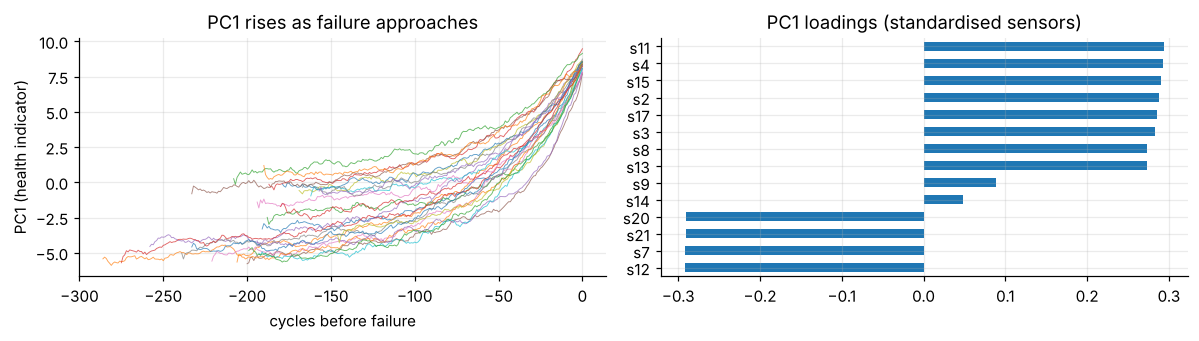

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for u in fit_units[:25]:
    ax[0].plot(np.arange(len(seq_train[u]))[::-1] * -1, seq_train[u][:, 0], lw=.6, alpha=.7)
ax[0].set_xlabel("cycles before failure"); ax[0].set_ylabel("PC1 (health indicator)"); ax[0].set_title("PC1 rises as failure approaches")
sens_load = pd.Series(fp.pca_.components_[0] * fp.sign_[0], index=SENSORS).sort_values()
sens_load.plot.barh(ax=ax[1]); ax[1].set_title("PC1 loadings (standardised sensors)")
plt.tight_layout(); savefig("fig03_pc1"); plt.show()

## 4. Model formulation
We model the hidden **machine-health condition** $z_t\in\{1,\dots,K\}$ at cycle $t$ as a first-order Markov chain and the PCA feature vector $x_t\in\mathbb R^3$ as a Gaussian emission:

$$P(z_1=i)=\pi_i,\qquad P(z_t=j\mid z_{t-1}=i)=A_{ij},\qquad x_t\mid z_t=k\sim\mathcal N\!\big(\mu_k,\operatorname{diag}(\sigma_k^2)\big).$$

Because wear never reverses, we use a **left-to-right topology**: $\pi_K=0$, $A_{ij}=0$ for $j\notin\{i,i+1\}$ and the last state is absorbing. State $K$ is the **Critical** state. Engines start with different (normal) initial wear, so the start distribution $\pi$ is **learned over the non-final states** rather than fixed to state 1. $K$ is chosen on validation engines (Section 7).

* **Training (maximum likelihood):** Baum–Welch (EM) over all fit engines jointly.
* **Initialisation (unsupervised):** each engine is cut into $K$ equal time chunks → initial state means/variances (uses only the position in time, no RUL).
* **Alert rule:** raise an alert when the *filtered* probability $P(z_t=K\mid x_{1:t})\ge\tau$ for 3 consecutive cycles; $\tau$ tuned on validation engines.

## 5. Algorithm implementation (from scratch)
`src/pmhmm/hmm_scratch.py` implements, in NumPy only (no HMM library):

| Algorithm | Method in `GaussianHMM` |
|---|---|
| Scaled **Forward** (scaling factors $c_t$; $\ln p(X)=\sum_t \ln c_t$) | `_scaled_forward`, `forward` |
| Scaled **Backward** | `_scaled_backward` |
| **Forward-Backward** smoothing ($\gamma_t(i)$, $\xi_t(i,j)$) | `forward_backward`, `smooth` |
| **Viterbi** (log domain) | `viterbi` |
| **Maximum-likelihood estimation** (Baum–Welch/EM) | `fit` |
| AIC / BIC | `aic_bic` |

EM converged in 83 iterations; log-likelihood -51879 -> -38530;  monotone non-decreasing: True


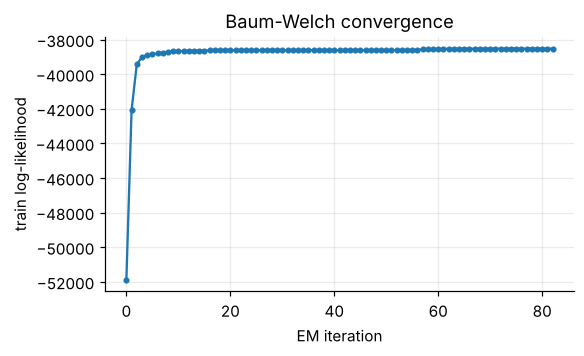

In [8]:
model = P.fit_hmm(P.prepare())          # K = 6 states, left-to-right, trained on fit engines only
K = model.n_states
h = np.array(model.loglik_history_)
print(f"EM converged in {len(h)} iterations; log-likelihood {h[0]:.0f} -> {h[-1]:.0f};  monotone non-decreasing: {bool((np.diff(h) > -1e-6).all())}")
plt.figure(figsize=(5.5, 3)); plt.plot(h, marker="o", ms=3); plt.xlabel("EM iteration"); plt.ylabel("train log-likelihood"); plt.title("Baum-Welch convergence")
savefig("fig04_em"); plt.show()

**Why scaling matters.** Multiplying hundreds of small densities underflows. We tile one engine 15× (≈ 4,000 steps) and compare an unscaled forward pass with the scaled one:

In [9]:
from pmhmm.hmm_scratch import _log_gauss_diag
X = np.tile(seq_train[fit_units[0]], (15, 1))
B = np.exp(_log_gauss_diag(X, model.means_, model.covars_))
a = model.startprob_ * B[0]
for t in range(1, len(X)):
    a = (a @ model.transmat_) * B[t]               # NO scaling
print(f"T = {len(X)}   unscaled forward likelihood = {a.sum():.3e}   (underflowed to zero)")
print(f"scaled forward log-likelihood = {model.score(X):.1f}   (finite)")

T = 2880   unscaled forward likelihood = 0.000e+00   (underflowed to zero)
scaled forward log-likelihood = -35646.8   (finite)


## 6. Verification against a reference implementation (hmmlearn) and baselines
**(a)** With *identical* parameters, our Forward / Forward-Backward / Viterbi must reproduce hmmlearn exactly.  
**(b)** Trained *independently* with identical constraints (left-to-right, same initialisation), the two EM implementations should reach (almost) the same model.

In [10]:
from hmmlearn.hmm import GaussianHMM as RefHMM
prep = P.prepare()
fit_seqs = prep.fit_seqs
Xcat, lens = np.vstack(fit_seqs), [len(s) for s in fit_seqs]
val_u = prep.val_units

# (a) identical parameters
ref = RefHMM(K, covariance_type="diag", init_params="")
ref.startprob_ = model.startprob_.copy()
ref.transmat_ = model.transmat_.copy(); ref.means_, ref.covars_ = model.means_, model.covars_
u0 = val_u[0]; Xv = prep.seq_train[u0]
rows = [("log-likelihood (all fit engines)", sum(model.score(s) for s in fit_seqs), ref.score(Xcat, lens)),
        ("max |gamma_ours - gamma_hmmlearn| (engine %d)" % u0, float(np.abs(model.smooth(Xv) - ref.predict_proba(Xv)).max()), 0.0),
        ("Viterbi path identical (engine %d)" % u0, bool((model.viterbi(Xv)[0] == ref.predict(Xv)).all()), True)]
print(pd.DataFrame(rows, columns=["check (same parameters)", "ours", "hmmlearn"]).to_string(index=False))

# (b) independent training, same constraints
init = GaussianHMM(K).init_from_time_segments(fit_seqs)
ref2 = RefHMM(K, covariance_type="diag", init_params="", params="stmc", n_iter=300, tol=1e-6, min_covar=1e-3, covars_prior=0.0, covars_weight=0.0)
ref2.startprob_ = init.startprob_.copy(); ref2.transmat_ = init.transmat_.copy(); ref2.means_ = init.means_.copy(); ref2.covars_ = init.covars_.copy()
ref2.fit(Xcat, lens)
agree = np.mean([(model.viterbi(prep.seq_train[u])[0] == ref2.predict(prep.seq_train[u])).mean() for u in val_u])
print(f"\nindependent training -> train log-lik ours {sum(model.score(s) for s in fit_seqs):.2f} vs hmmlearn {ref2.score(Xcat, lens):.2f};"
      f"  max |A diff| = {np.abs(model.transmat_ - ref2.transmat_).max():.1e};  Viterbi agreement on validation engines = {agree:.4f}")

                     check (same parameters)         ours     hmmlearn
            log-likelihood (all fit engines) -38529.85125 -38529.85125
max |gamma_ours - gamma_hmmlearn| (engine 3)          0.0          0.0
           Viterbi path identical (engine 3)         True         True



independent training -> train log-lik ours -38529.85 vs hmmlearn -38529.85;  max |A diff| = 6.9e-06;  Viterbi agreement on validation engines = 1.0000


**(c) Baselines** (same features, same alert rule, threshold tuned on validation): a **GMM** (K components, no temporal model) and a plain **PC1 threshold**. Evaluated in Section 8.

## 7. Inference and model selection
Forward (filtering), Forward-Backward (smoothing) and Viterbi on a held-out engine:

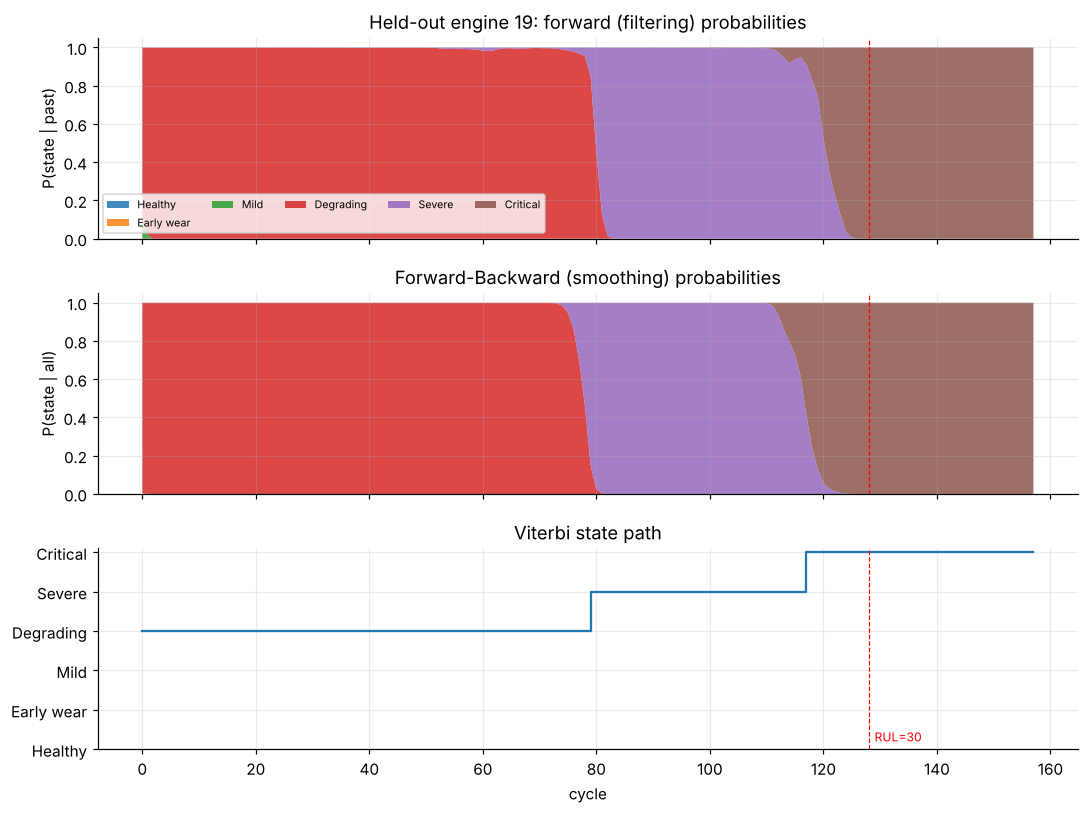

In [11]:
u = val_u[3]; X = prep.seq_train[u]; r = prep.rul_train[u]; T = len(X)
filt, ll = model.forward(X); smooth = model.smooth(X); vit, _ = model.viterbi(X)
names = P.STATE_NAMES
fig, ax = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
ax[0].stackplot(range(T), filt.T, labels=[names[i] for i in range(K)], alpha=.85); ax[0].set_ylabel("P(state | past)"); ax[0].set_title(f"Held-out engine {u}: forward (filtering) probabilities"); ax[0].legend(ncol=5, fontsize=7, loc="lower left")
ax[1].stackplot(range(T), smooth.T, alpha=.85); ax[1].set_ylabel("P(state | all)"); ax[1].set_title("Forward-Backward (smoothing) probabilities")
ax[2].step(range(T), vit, where="post"); ax[2].set_yticks(range(K)); ax[2].set_yticklabels([names[i] for i in range(K)]); ax[2].set_title("Viterbi state path"); ax[2].set_xlabel("cycle")
for a in ax: a.axvline(T - FAULT_RUL, color="r", ls="--", lw=.8)
ax[2].text(T - FAULT_RUL + 1, 0.2, "RUL=30", color="r", fontsize=8)
plt.tight_layout(); savefig("fig05_inference"); plt.show()

**Choosing the number of states $K$** (selection uses validation engines only; the `test_F1_FYI_only` column is shown purely for transparency and is *not* used for any decision). Likelihood-based criteria keep improving as $K$ grows (typical for HMMs), so we select $K$ by the **validation fault-F1** of the alert rule, restricted to $K\in\{3,4,5,6\}$ so each state stays interpretable. Rule (parsimony): *the smallest $K$ whose validation F1 is within 0.01 of the best*, because differences below that are noise on 30 validation engines:

,K,tuned_threshold,train_loglik,val_loglik_per_cycle,AIC,BIC,val_fault_F1,val_fault_recall,val_mean_lead,test_F1_FYI_only
0,2,0.999,-56324.232,-3.994,112674.464,112773.389,0.492,0.985,92.000,0.208
1,3,0.999,-48278.598,-3.346,96599.195,96758.998,0.765,0.923,42.800,0.543
2,4,0.999,-44067.679,-3.052,88193.358,88414.038,0.783,0.912,40.233,0.585
3,5,0.999,-40940.266,-2.891,81954.531,82236.089,0.806,0.908,37.833,0.617
4,6,0.050,-38529.851,-2.712,77149.702,77492.137,0.825,0.745,24.000,0.596


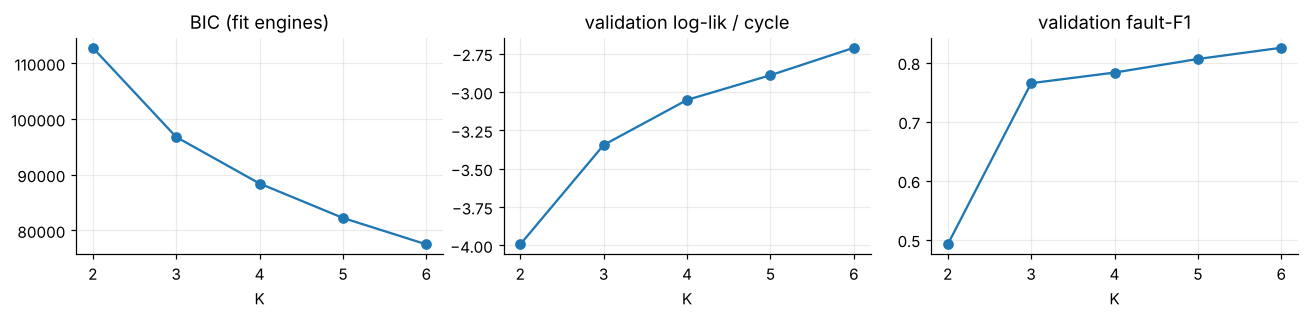

selected K (smallest K within 0.01 of the best validation F1, K in 3..6): 6


In [12]:
val_seqs = {u: prep.seq_train[u] for u in prep.val_units}; val_rul = {u: prep.rul_train[u] for u in prep.val_units}
n_val = sum(len(x) for x in val_seqs.values()); rows = []
for k in [2, 3, 4, 5, 6]:
    m = GaussianHMM(k).fit(fit_seqs)
    aic, bic = m.aic_bic(fit_seqs)
    sc = {u: m.forward(X)[0][:, -1] for u, X in val_seqs.items()}
    thr = tune_threshold(sc, val_rul, P.HMM_GRID); ev = evaluate_alerts(sc, val_rul, thr)
    st = {u: m.forward(X)[0][:, -1] for u, X in prep.seq_test.items()}; tev = evaluate_alerts(st, prep.rul_test, thr)
    rows.append(dict(K=k, tuned_threshold=thr, train_loglik=sum(m.score(s) for s in fit_seqs), val_loglik_per_cycle=sum(m.score(X) for X in val_seqs.values()) / n_val,
                     AIC=aic, BIC=bic, val_fault_F1=ev["f1"], val_fault_recall=ev["fault_recall"], val_mean_lead=ev["mean_lead_time"], test_F1_FYI_only=tev["f1"]))
sel = pd.DataFrame(rows).round(3); display(sel)
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(sel.K, sel.BIC, marker="o"); ax[0].set_title("BIC (fit engines)")
ax[1].plot(sel.K, sel.val_loglik_per_cycle, marker="o"); ax[1].set_title("validation log-lik / cycle")
ax[2].plot(sel.K, sel.val_fault_F1, marker="o"); ax[2].set_title("validation fault-F1")
for a in ax: a.set_xlabel("K")
plt.tight_layout(); savefig("fig06_model_selection"); plt.show()
cand = sel[sel.K.between(3, 6)]; best_k = int(cand[cand.val_fault_F1 >= cand.val_fault_F1.max() - 0.01].K.min())
print("selected K (smallest K within 0.01 of the best validation F1, K in 3..6):", best_k); assert best_k == K

## 8. Evaluation

**Metrics** (as required for Project 1): *fault recall*, *F1* (cycle level, fault = RUL ≤ 30, with the alert latched once raised), *log-likelihood* (held-out) and *detection lead time* (true RUL at the first alert = number of cycles of warning before failure). We also report precision, false-positive rate and *engine recall* (share of engines that are already inside the fault zone at the end of their observation and were alerted).

In [13]:
res = P.run_all(prep, model)
tab = pd.DataFrame({(split, k): {m: v[split][k] for m, v in res.items()} for split in ["val", "test"]
                    for k in ["fault_recall", "precision", "f1", "false_positive_rate", "engine_recall", "mean_lead_time", "median_lead_time"]}).T.round(3)
display(tab)
print({m: round(v["threshold"], 3) for m, v in res.items()}, "<- thresholds tuned on validation only")
ll_test = sum(model.score(X) for X in prep.seq_test.values()) / sum(len(x) for x in prep.seq_test.values())
ll_val  = sum(model.score(X) for X in val_seqs.values()) / n_val
print(f"held-out log-likelihood per cycle: validation {ll_val:.3f} | test {ll_test:.3f}")

HMM (from scratch)  GMM (no temporal model)  \
val  fault_recall                      0.745                    0.481   
     precision                         0.924                    0.910   
     f1                                0.825                    0.629   
     false_positive_rate               0.012                    0.009   
     engine_recall                     1.000                    0.567   
     mean_lead_time                   24.000                   27.882   
     median_lead_time                 22.000                   29.000   
test fault_recall                      0.485                    0.334   
     precision                         0.774                    1.000   
     f1                                0.596                    0.501   
     false_positive_rate               0.004                    0.000   
     engine_recall                     0.600                    0.320   
     mean_lead_time                   27.125                   25.250   
     median_lead_time                 23.500                   26.000   

                          PC1 threshold  
val  fault_recall                 0.854  
     precision                    0.825  
     f1                           0.839  
     false_positive_rate          0.035  
     engine_recall                1.000  
     mean_lead_time              31.067  
     median_lead_time            29.000  
test fault_recall                 0.672  
     precision                    0.556  
     f1                           0.608  
     false_positive_rate          0.014  
     engine_recall                0.720  
     mean_lead_time              39.250  
     median_lead_time            30.000

{'HMM (from scratch)': 0.05, 'GMM (no temporal model)': 0.05, 'PC1 threshold': 3.085} <- thresholds tuned on validation only
held-out log-likelihood per cycle: validation -2.712 | test -2.200


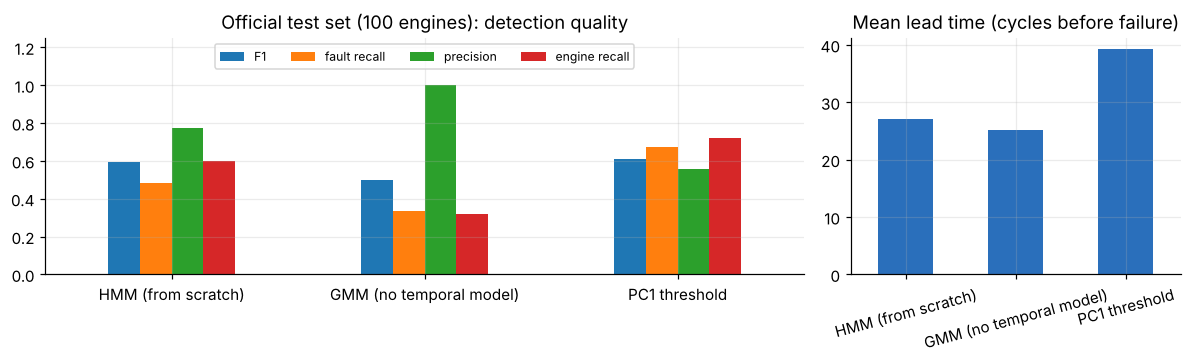

In [14]:
test_tab = pd.DataFrame({m: {k: v["test"][k] for k in ["f1", "fault_recall", "precision", "engine_recall", "mean_lead_time"]} for m, v in res.items()}).T
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2.3, 1]})
test_tab[["f1", "fault_recall", "precision", "engine_recall"]].rename(columns={"f1": "F1", "fault_recall": "fault recall", "precision": "precision", "engine_recall": "engine recall"}).plot.bar(ax=ax[0], rot=0, ylim=(0, 1.25))
ax[0].set_title("Official test set (100 engines): detection quality"); ax[0].legend(fontsize=8, ncol=4, loc="upper center")
test_tab["mean_lead_time"].plot.bar(ax=ax[1], rot=15, color="#2a6fbb"); ax[1].set_title("Mean lead time (cycles before failure)")
plt.tight_layout(); savefig("fig07_test_comparison"); plt.show()

## 9. Visualization

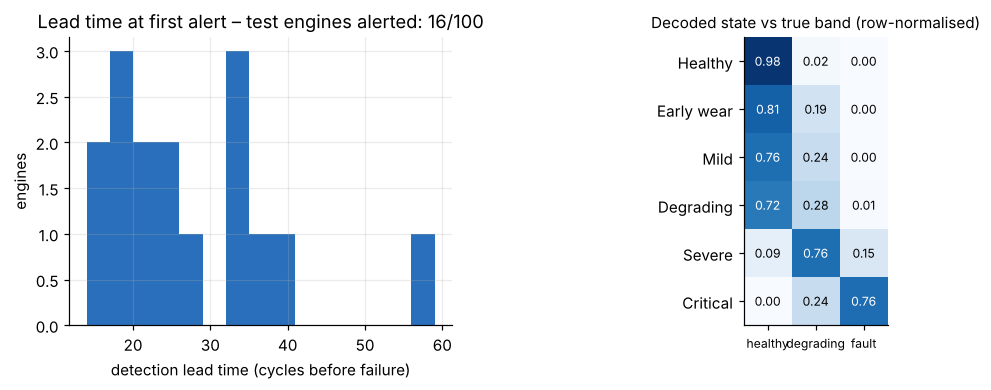

In [15]:
sc_test = P.hmm_fault_scores(model, prep.seq_test); thr = res["HMM (from scratch)"]["threshold"]
leads, alert_rul = [], []
for u, s in sc_test.items():
    a = first_alert(s, thr)
    if a >= 0: leads.append(prep.rul_test[u][a])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(leads, bins=15, color="#2a6fbb"); ax[0].set_xlabel("detection lead time (cycles before failure)"); ax[0].set_ylabel("engines")
ax[0].set_title(f"Lead time at first alert – test engines alerted: {len(leads)}/100")
# Viterbi states vs ground-truth health bands (all test cycles)
vit_all = np.concatenate([model.viterbi(X)[0] for X in prep.seq_test.values()]); band_all = np.concatenate([health_band(prep.rul_test[u]) for u in prep.seq_test])
ct = pd.crosstab(pd.Series(vit_all, name="Viterbi state").map(P.STATE_NAMES), pd.Series(band_all, name="true band").map({0: "healthy", 1: "degrading", 2: "fault"}), normalize="index")
ct = ct.reindex([P.STATE_NAMES[i] for i in range(K)])[["healthy", "degrading", "fault"]]
im = ax[1].imshow(ct.values, cmap="Blues", vmin=0, vmax=1); ax[1].set_xticks(range(3)); ax[1].set_xticklabels(ct.columns, fontsize=8); ax[1].set_yticks(range(K)); ax[1].set_yticklabels(ct.index)
for i in range(K):
    for j in range(3): ax[1].text(j, i, f"{ct.values[i, j]:.2f}", ha="center", va="center", color="white" if ct.values[i, j] > .5 else "black", fontsize=8)
ax[1].set_title("Decoded state vs true band (row-normalised)", fontsize=10); ax[1].grid(False)
plt.subplots_adjust(wspace=0.45); savefig("fig08_lead_and_states"); plt.show()

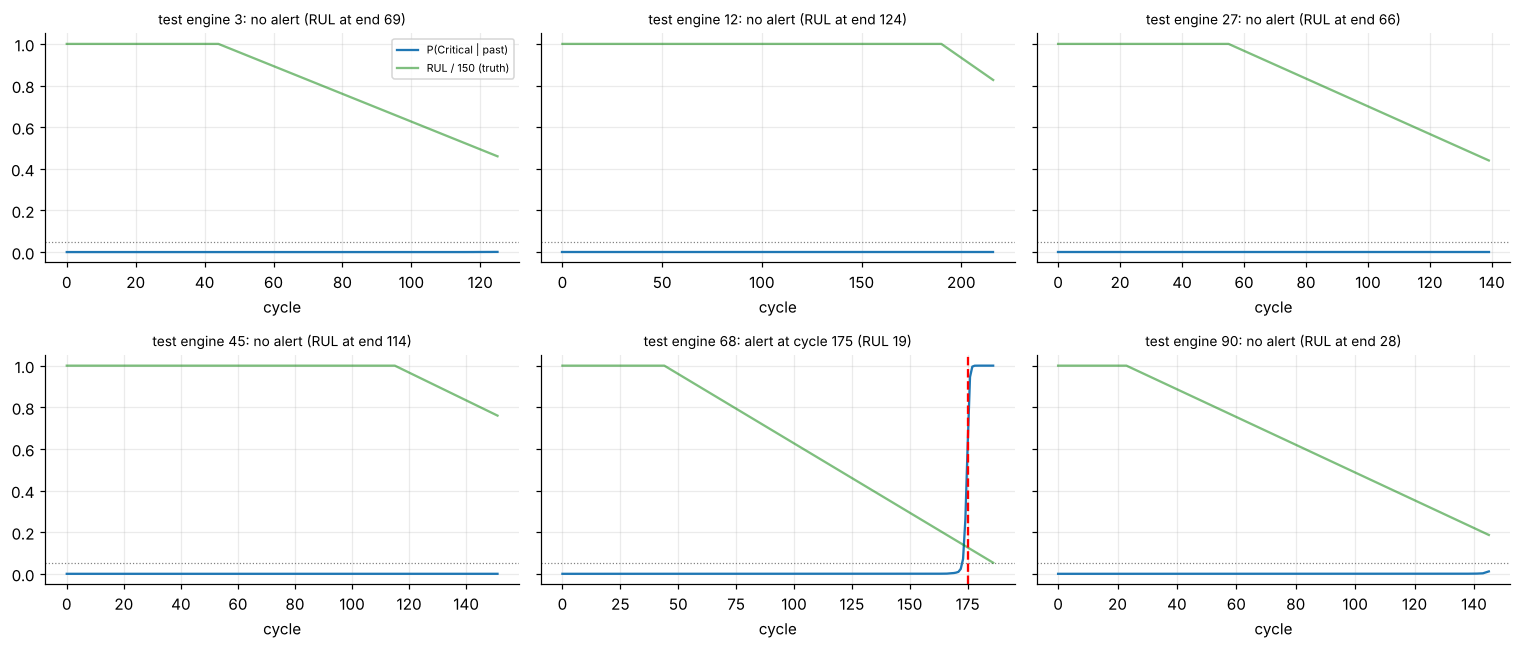

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(14, 6), sharey=True)
for ax, u in zip(axes.ravel(), [3, 12, 27, 45, 68, 90]):
    s = sc_test[u]; a = first_alert(s, thr); T = len(s)
    ax.plot(s, label="P(Critical | past)"); ax.axhline(thr, color="gray", ls=":", lw=.8)
    ax.plot(np.clip(prep.rul_test[u], 0, 150) / 150, color="green", alpha=.5, label="RUL / 150 (truth)")
    if a >= 0: ax.axvline(a, color="r", ls="--"); ax.set_title(f"test engine {u}: alert at cycle {a} (RUL {prep.rul_test[u][a]})", fontsize=9)
    else: ax.set_title(f"test engine {u}: no alert (RUL at end {prep.rul_test[u][-1]})", fontsize=9)
    ax.set_xlabel("cycle")
axes[0, 0].legend(fontsize=7); plt.tight_layout(); savefig("fig09_engine_alerts"); plt.show()

## 10. Interpretation

In [17]:
A = model.transmat_; dwell = 1 / (1 - np.diag(A)[:-1])
vit_val = {u: model.viterbi(X)[0] for u, X in val_seqs.items()}
rul_by_state = pd.Series(np.concatenate([val_rul[u] for u in val_seqs])).groupby(np.concatenate(list(vit_val.values()))).mean()
interp = pd.DataFrame({"state": [P.STATE_NAMES[i] for i in range(K)],
                       "mean PC1": model.means_[:, 0].round(2),
                       "expected dwell (cycles)": list(dwell.round(1)) + ["absorbing"],
                       "mean true RUL when decoded (validation)": rul_by_state.round(1).values})
display(interp)
t = res["HMM (from scratch)"]["test"]; g = res["GMM (no temporal model)"]["test"]; p = res["PC1 threshold"]["test"]
print(f"Test: HMM F1 {t['f1']:.3f} vs PC1-threshold {p['f1']:.3f} vs GMM {g['f1']:.3f}; HMM fault recall {t['fault_recall']:.3f}, engine recall {t['engine_recall']:.2f}, mean lead {t['mean_lead_time']:.1f} cycles")

,state,mean PC1,expected dwell (cycles),mean true RUL when decoded (validation)
0,Healthy,-4.47,83.3,167.7
1,Early wear,-2.78,57.3,113.7
2,Mild,-1.03,50.1,124.5
3,Degrading,0.60,39.0,107.9
4,Severe,2.41,35.1,48.8
5,Critical,6.07,absorbing,14.5


Test: HMM F1 0.596 vs PC1-threshold 0.608 vs GMM 0.501; HMM fault recall 0.485, engine recall 0.60, mean lead 27.1 cycles


**What the results mean**
* The decoded states form a wear ladder: the mean PC1 rises state by state and the **mean true RUL falls** from *Healthy* towards *Critical* (the ladder is not perfectly monotone in the middle states) – recovered **without ever seeing RUL labels**. Engines may enter the ladder at different rungs because of different initial wear.
* Alerts from the **filtered** probability of the Critical state fire a few tens of cycles before failure on average (lead-time histogram / table above), using only past data.
* **Honest comparison:** on the official test set the HMM alert is very precise but has lower recall than the simple PC1 threshold, and its F1 is slightly *below* the tuned PC1 threshold; it clearly beats the non-temporal GMM. We therefore do **not** claim an accuracy advantage over a tuned threshold. The HMM's added value is the *probabilistic state ladder* (uncertainty, dwell times, smoothed/Viterbi explanations) that a bare threshold does not provide.
* With 30 validation engines, F1 differences of about 0.01–0.02 between $K$ values are within noise (see the sensitivity table).

**Limitations.** (1) Single operating condition/fault mode (FD001); FD002–FD004 would need operating-condition normalisation. (2) Simulated data. (3) Thresholds and $K$ depend on the 70/30 engine split (seed 42). (4) Only 25 of the 100 test engines end inside the fault zone, so engine-level recall rests on a small count. (5) Educational prototype – **not** a production maintenance system.

## 11. Save artifacts (used by the Streamlit dashboard)

In [18]:
P.save_artifacts(prep, model, res)
print("saved to", P.ARTIFACT_DIR, "->", sorted(p.name for p in P.ARTIFACT_DIR.iterdir()))

saved to /home/claude/predictive-maintenance-hmm/artifacts -> ['feature_pipeline.joblib', 'hmm_params.npz', 'results.json', 'split.json']
